# Superstore Sales Analysis

**Goal:** find out where the store makes and loses money, and what the business should change.

**Steps in this notebook**
1. Load the raw CSV with pandas
2. Clean it (missing values, duplicates, data types) and pull out the hidden Returns list
3. Save the clean data into a SQLite database (two tables: `orders` and `returns`)
4. Run the SQL queries from `queries.sql`
   - Part 1: core business questions
   - Part 2: deeper analysis (CTEs, window functions, JOINs)
5. Make 5 charts and save them as PNG files in `images/`

## 0. Imports

In [1]:
import sqlite3                    # built into Python: lets us create and query a SQLite database
import pandas as pd               # tables (DataFrames) for loading and cleaning data
import matplotlib.pyplot as plt   # the main plotting library
import matplotlib.ticker as mtick # helpers to format axis numbers (e.g. $ and %)
import seaborn as sns             # sits on top of matplotlib, gives nicer default styling

# Show money with 2 decimals instead of scientific notation like 1.2e+05
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the raw data

The Kaggle copy of this file is saved in the *latin-1* encoding, while some other copies are *UTF-8*.
We try UTF-8 first and fall back to latin-1 if Python can't read it.

In [2]:
CSV_PATH = "data/superstore.csv"

try:
    raw = pd.read_csv(CSV_PATH, encoding="utf-8")
except UnicodeDecodeError:
    raw = pd.read_csv(CSV_PATH, encoding="latin-1")

print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [3]:
# info() lists every column, how many non-empty values it has, and its data type
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

## 2. Clean the data

### 2a. Missing values
First we count the empty cells in each column.

In [4]:
# isna() marks empty cells as True; sum() counts the Trues per column
raw.isna().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Two kinds of gaps show up:

* **Rows with no order date, sales or profit.** These are not real orders. In this copy of the file,
  the "Returns" and "People" lists from the original Excel workbook were pasted underneath the orders.
  We drop any row that is missing one of these key fields.
* **Postal Code** is empty for a few real orders (all from Burlington, Vermont). Postal code is not used
  in the analysis, so we keep those rows and write `"Unknown"` instead of deleting good sales data.

**Before dropping those rows:** the Returns list says which orders customers sent back, which is useful.
So we first copy it into its own table, `returns`.

In [5]:
# In the pasted Returns list, its "Returned" column (always "Yes") landed under "Row ID",
# and the returned order's ID landed under "Order ID".
returns = raw.loc[raw["Row ID"] == "Yes", ["Order ID"]]
returns = returns.rename(columns={"Order ID": "order_id"})
print("Rows in the Returns list:", len(returns))

# The Kaggle copy of the dataset doesn't include the Returns list
if len(returns) == 0:
    print("No Returns list in this CSV - the return queries (Q12, Q13) will show 0%.")

Rows in the Returns list: 800


In [6]:
# Work on a copy so the raw data stays untouched
df = raw.copy()

rows_before = len(df)
# Keep only rows that have all the key fields we need for the analysis
df = df.dropna(subset=["Order ID", "Order Date", "Sales", "Profit"])
print("Rows dropped (not real orders):", rows_before - len(df))

Rows dropped (not real orders): 806


In [7]:
# Postal codes are labels, not numbers, so we store them as text.
# Int64 removes the '.0' pandas added, zfill(5) puts back leading zeros (e.g. 5401 -> 05401).
df["Postal Code"] = df["Postal Code"].astype("Int64").astype("string").str.zfill(5)
df["Postal Code"] = df["Postal Code"].fillna("Unknown")

# Check: every column should now show 0 missing values
df.isna().sum().sum()

np.int64(0)

### 2b. Duplicates

In [8]:
# duplicated() flags a row that is an exact copy of an earlier row
print("Exact duplicate rows:", df.duplicated().sum())

# Row ID should be unique too (one ID per order line)
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

# Remove duplicates (safe to run even when there are none)
df = df.drop_duplicates()

Exact duplicate rows: 0
Duplicate Row IDs: 0


In [9]:
# The Returns list has one row per returned PRODUCT LINE, so an order with 3 returned
# products shows up 3 times. We only need to know which ORDERS were returned, once each.
print("Duplicate order IDs in returns:", returns.duplicated().sum())
returns = returns.drop_duplicates()
print("Unique returned orders:", len(returns))

Duplicate order IDs in returns:

 504
Unique returned orders: 296


### 2c. Data types
* The dates were read as text, so we convert them to real dates (needed for monthly grouping).
* `Row ID` and `Quantity` were read as text/decimals because of the extra rows we removed; they should be whole numbers.

In [10]:
# The dates look like 11/8/2017, i.e. month/day/year
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)

### 2d. Tidy column names
SQL is easier to write when column names have no spaces or dashes, e.g. `sub_category` instead of `Sub-Category`.

In [11]:
df.columns = (
    df.columns.str.lower()            # 'Sub-Category' -> 'sub-category'
    .str.replace(" ", "_")            # 'order date'   -> 'order_date'
    .str.replace("-", "_")            # 'sub-category' -> 'sub_category'
)

print("Clean data:", df.shape)
print("Date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())
df.dtypes

Clean data:

 (9994, 21)
Date range: 2015-01-03 to 2018-12-30


row_id                    int64
order_id                    str
order_date       datetime64[us]
ship_date        datetime64[us]
ship_mode                   str
customer_id                 str
customer_name               str
segment                     str
country                     str
city                        str
state                       str
postal_code              string
region                      str
product_id                  str
category                    str
sub_category                str
product_name                str
sales                   float64
quantity                  int64
discount                float64
profit                  float64
dtype: object

## 3. Load the clean data into SQLite

In [12]:
# connect() creates the database file if it doesn't exist yet
conn = sqlite3.connect("superstore.db")

# Write the DataFrame as a table called 'orders'.
# if_exists="replace" means re-running the notebook rebuilds the table instead of adding rows twice.
df.to_sql("orders", conn, if_exists="replace", index=False)
returns.to_sql("returns", conn, if_exists="replace", index=False)

# Quick check with SQL: each table should have as many rows as its DataFrame
pd.read_sql_query(
    "SELECT 'orders' AS table_name, COUNT(*) AS row_count FROM orders "
    "UNION ALL "
    "SELECT 'returns', COUNT(*) FROM returns",
    conn,
)

,table_name,row_count
0,orders,9994
1,returns,296


## 4. Run the SQL queries

All queries live in `queries.sql`. We read the file and split it on `;` so each query becomes one item in a list.
`queries[0]` is Q1, `queries[1]` is Q2, and so on.

In [13]:
with open("queries.sql", encoding="utf-8") as f:
    sql_text = f.read()

# split(";") cuts the text at every semicolon; strip() removes blank space; empty pieces are skipped
queries = [q.strip() for q in sql_text.split(";") if q.strip()]
print("Queries loaded:", len(queries))


def run_query(number):
    """Run query number N (1 = Q1) from queries.sql and return the result as a DataFrame."""
    return pd.read_sql_query(queries[number - 1], conn)

Queries loaded: 14


## Part 1: Core business questions

### Q1. Top 5 products by profit

In [14]:
top_products = run_query(1)
top_products

,product_name,category,total_sales,total_profit
0,Canon imageCLASS 2200 Advanced Copier,Technology,"61,599.82","25,199.93"
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,"27,453.38","7,753.04"
2,Hewlett Packard LaserJet 3310 Copier,Technology,"18,839.69","6,983.88"
3,Canon PC1060 Personal Laser Copier,Technology,"11,619.83","4,570.93"
4,HP Designjet T520 Inkjet Large Format Printer ...,Technology,"18,374.90","4,094.98"


### Q2. Profit by region (top region first)

In [15]:
regions = run_query(2)
regions

,region,total_sales,total_profit,profit_margin_pct
0,West,"725,457.82","108,418.45",14.90
1,East,"678,781.24","91,522.78",13.50
2,South,"391,721.91","46,749.43",11.90
3,Central,"501,239.89","39,706.36",7.90


### Q3. Profit by category

In [16]:
categories = run_query(3)
categories

,category,total_sales,total_profit,profit_margin_pct
0,Technology,"836,154.03","145,454.95",17.40
1,Office Supplies,"719,047.03","122,490.80",17.00
2,Furniture,"741,999.80","18,451.27",2.50


### Q4. Profit by sub-category

In [17]:
sub_categories = run_query(4)
sub_categories

,category,sub_category,total_profit
0,Technology,Copiers,"55,617.82"
1,Technology,Phones,"44,515.73"
2,Technology,Accessories,"41,936.64"
3,Office Supplies,Paper,"34,053.57"
4,Office Supplies,Binders,"30,221.76"
5,Furniture,Chairs,"26,590.17"
6,Office Supplies,Storage,"21,278.83"
7,Office Supplies,Appliances,"18,138.01"
8,Furniture,Furnishings,"13,059.14"
9,Office Supplies,Envelopes,"6,964.18"


### Q5. Loss-making categories (sub-category level)

In [18]:
loss_makers = run_query(5)
loss_makers

,category,sub_category,total_sales,total_profit
0,Furniture,Tables,"206,965.53","-17,725.48"
1,Furniture,Bookcases,"114,880.00","-3,472.56"
2,Office Supplies,Supplies,"46,673.54","-1,189.10"


### Q6. Monthly sales trend

In [19]:
monthly = run_query(6)

# 48 months is a long table, so show the first 5 and last 5 rows
pd.concat([monthly.head(), monthly.tail()])

,month,orders,total_sales,total_profit
0,2015-01,32,"14,236.90","2,450.19"
1,2015-02,28,"4,519.89",862.31
2,2015-03,71,"55,691.01",498.73
3,2015-04,66,"28,295.35","3,488.84"
4,2015-05,69,"23,648.29","2,738.71"
43,2018-08,111,"63,120.89","9,040.96"
44,2018-09,226,"87,866.65","10,991.56"
45,2018-10,147,"77,776.92","9,275.28"
46,2018-11,261,"118,447.82","9,690.10"
47,2018-12,224,"83,829.32","8,483.35"


### Q7. Discount vs profit

In [20]:
discounts = run_query(7)
discounts

,discount,order_lines,avg_profit_per_line,total_profit
0,0.00,4798,66.90,"320,987.60"
1,0.10,94,96.06,"9,029.18"
2,0.15,52,27.29,"1,418.99"
3,0.20,3657,24.70,"90,337.31"
4,0.30,227,-45.68,"-10,369.28"
5,0.32,27,-88.56,"-2,391.14"
6,0.40,206,-111.93,"-23,057.05"
7,0.45,11,-226.65,"-2,493.11"
8,0.50,66,-310.70,"-20,506.43"
9,0.60,138,-43.08,"-5,944.66"


### Q8. Top 10 customers by sales

In [21]:
top_customers = run_query(8)
top_customers

,customer_name,segment,orders,total_sales,total_profit
0,Sean Miller,Home Office,5,"25,043.05","-1,980.74"
1,Tamara Chand,Corporate,5,"19,052.22","8,981.32"
2,Raymond Buch,Consumer,6,"15,117.34","6,976.10"
3,Tom Ashbrook,Home Office,4,"14,595.62","4,703.79"
4,Adrian Barton,Consumer,10,"14,473.57","5,444.81"
5,Ken Lonsdale,Consumer,12,"14,175.23",806.85
6,Sanjit Chand,Consumer,9,"14,142.33","5,757.41"
7,Hunter Lopez,Consumer,6,"12,873.30","5,622.43"
8,Sanjit Engle,Consumer,11,"12,209.44","2,650.68"
9,Christopher Conant,Consumer,5,"12,129.07","2,177.05"


## Part 2: Deeper analysis
These queries use more advanced SQL. Each one has comments in `queries.sql` explaining the new idea.

| Query | SQL idea | Question |
|---|---|---|
| Q9 | CTE + `LAG()` | How fast are sales growing each year? |
| Q10 | CTE + `RANK() OVER (PARTITION BY ...)` | What are the top 3 products in each region? |
| Q11 | `SUM() OVER (...)` running total | How do sales build up through each year? |
| Q12 | `LEFT JOIN` to the returns table | Which regions have the most returns? |
| Q13 | `LEFT JOIN` + `CASE WHEN` | Which sub-categories get returned most? |
| Q14 | `CASE WHEN` bands | Do discounts cause the losses, or is it just the products? |

### Q9. Year-over-year sales growth

In [22]:
yearly = run_query(9)
yearly

,year,total_sales,previous_year_sales,sales_growth_pct,profit_margin_pct
0,2015,"484,247.50",NaN,NaN,10.20
1,2016,"470,532.51","484,247.50",-2.80,13.10
2,2017,"609,205.60","470,532.51",29.50,13.40
3,2018,"733,215.26","609,205.60",20.40,12.70


### Q10. Top 3 products in each region

In [23]:
top_per_region = run_query(10)
top_per_region

,region,profit_rank,product_name,total_profit
0,Central,1,Canon imageCLASS 2200 Advanced Copier,"8,399.98"
1,Central,2,GBC Ibimaster 500 Manual ProClick Binding System,"3,804.90"
2,Central,3,Canon PC1060 Personal Laser Copier,"2,302.97"
3,East,1,Canon imageCLASS 2200 Advanced Copier,"10,079.97"
4,East,2,Ativa V4110MDD Micro-Cut Shredder,"3,772.95"
5,East,3,"3D Systems Cube Printer, 2nd Generation, Magenta","3,717.97"
6,South,1,Fellowes PB500 Electric Punch Plastic Comb Bin...,"3,812.97"
7,South,2,HP Designjet T520 Inkjet Large Format Printer ...,"1,854.99"
8,South,3,Hewlett-Packard Deskjet 3050a All-in-One Color...,"1,459.20"
9,West,1,Canon imageCLASS 2200 Advanced Copier,"6,719.98"


### Q11. Running total of sales (year-to-date)

In [24]:
running = run_query(11)
running.head(12)   # the first year: watch sales_year_to_date build up month by month

,month,monthly_sales,sales_year_to_date
0,2015-01,"14,236.90","14,236.90"
1,2015-02,"4,519.89","18,756.79"
2,2015-03,"55,691.01","74,447.80"
3,2015-04,"28,295.35","102,743.14"
4,2015-05,"23,648.29","126,391.43"
5,2015-06,"34,595.13","160,986.56"
6,2015-07,"33,946.39","194,932.95"
7,2015-08,"27,909.47","222,842.42"
8,2015-09,"81,777.35","304,619.77"
9,2015-10,"31,453.39","336,073.16"


### Q12. Return rate by region

In [25]:
returns_by_region = run_query(12)
returns_by_region

,region,total_orders,returned_orders,return_rate_pct
0,West,1611,189,11.70
1,Central,1175,39,3.30
2,East,1401,44,3.10
3,South,822,24,2.90


### Q13. Returns by sub-category

In [26]:
returns_by_sub = run_query(13)
returns_by_sub

,sub_category,order_lines,returned_lines,return_rate_pct,returned_sales
0,Machines,115,13,11.30,"13,158.39"
1,Tables,319,30,9.40,"17,042.28"
2,Paper,1370,123,9.00,"7,140.28"
3,Binders,1523,137,9.00,"9,983.15"
4,Fasteners,217,19,8.80,213.09
5,Phones,889,77,8.70,"27,633.61"
6,Chairs,617,53,8.60,"25,154.70"
7,Appliances,466,40,8.60,"10,129.78"
8,Supplies,190,16,8.40,"3,195.96"
9,Accessories,775,61,7.90,"12,716.33"


### Q14. Is it the discount or the product?
The SQL result is a long list (one row per sub-category and discount band).
`pivot()` reshapes it into a grid that's easier to read: one row per sub-category, one column per discount band.
An empty cell (NaN) means that sub-category never got a discount that large.

In [27]:
discount_check = run_query(14)

margin_grid = discount_check.pivot(index="sub_category", columns="discount_band", values="profit_margin_pct")
margin_grid

discount_band,1. No discount,2. 1-20%,3. Over 20%
sub_category,,,
Accessories,29.80,13.60,NaN
Appliances,29.70,13.70,-255.10
Art,29.90,12.60,NaN
Binders,48.00,34.40,-106.60
Bookcases,19.00,2.80,-38.90
Chairs,24.10,6.80,-9.60
Copiers,46.50,31.80,12.90
Envelopes,46.90,33.90,NaN
Fasteners,35.80,24.70,NaN


In [28]:
# Of the sub-categories that ever got a discount over 20%, how many lost money at that level?
big = margin_grid["3. Over 20%"].dropna()   # dropna() skips sub-categories with no big discounts
print(f"{(big < 0).sum()} of {len(big)} sub-categories have a negative margin when discounted over 20%")

# The same product line at full price vs heavily discounted
print("Tables margin at no discount:", margin_grid.loc["Tables", "1. No discount"], "%")
print("Tables margin when discounted over 20%:", margin_grid.loc["Tables", "3. Over 20%"], "%")

8 of 9 sub-categories have a negative margin when discounted over 20%
Tables margin at no discount: 18.5 %
Tables margin when discounted over 20%: -34.1 %


## 5. Charts

A few shared style settings first, so all four charts look like one set:
blue for normal/positive values, red only for losses, light grey grid lines.

In [29]:
BLUE = "#2a78d6"   # main bar/line color
RED = "#e34948"    # used only for negative profit (losses)
INK = "#0b0b0b"    # titles
GREY = "#52514e"   # axis labels and tick labels

sns.set_theme(style="whitegrid")       # white background with light grid lines
plt.rcParams.update({
    "figure.dpi": 110,                 # sharpness on screen
    "savefig.dpi": 150,                # sharpness of the saved PNG
    "axes.edgecolor": "#d6d5d0",
    "grid.color": "#e8e7e3",
    "axes.labelcolor": GREY,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
})

dollars = mtick.StrMethodFormatter("${x:,.0f}")   # 12000 -> $12,000


def sign_colors(values):
    """Return blue for each value >= 0 and red for each value < 0."""
    return [BLUE if v >= 0 else RED for v in values]

### Chart 1: Monthly sales trend

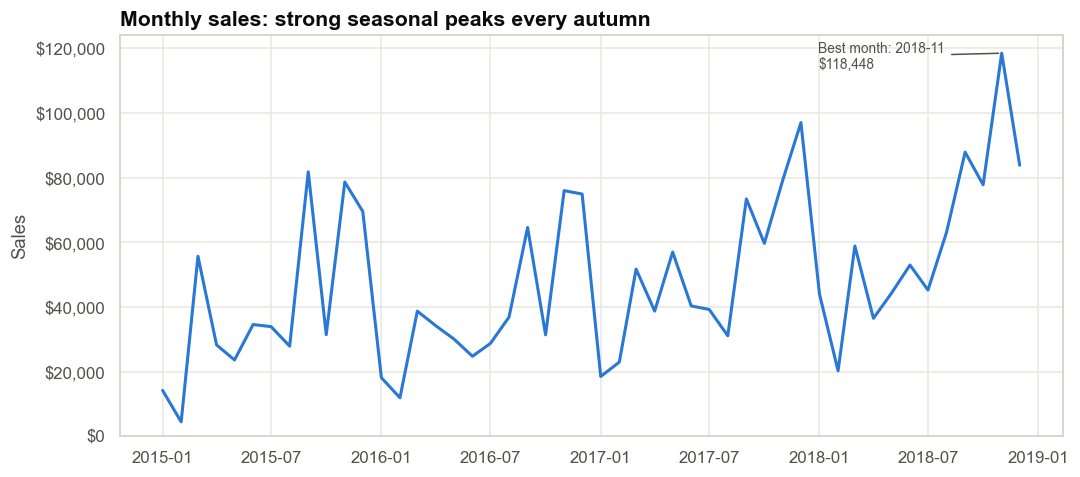

In [30]:
# Turn '2017-11' text into a real date so matplotlib spaces the months correctly
monthly["month_date"] = pd.to_datetime(monthly["month"])

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=monthly, x="month_date", y="total_sales", color=BLUE, linewidth=2, ax=ax)

# Label only the best month, not every point (keeps the chart clean)
best = monthly.loc[monthly["total_sales"].idxmax()]
ax.annotate(f"Best month: {best['month']}\n${best['total_sales']:,.0f}",
            xy=(best["month_date"], best["total_sales"]),
            xytext=(-120, -10), textcoords="offset points", color=GREY, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GREY))

ax.set_title("Monthly sales: strong seasonal peaks every autumn")
ax.set_xlabel("")
ax.set_ylabel("Sales")
ax.yaxis.set_major_formatter(dollars)
ax.set_ylim(bottom=0)                 # start the y-axis at 0 so the line isn't exaggerated

fig.tight_layout()
fig.savefig("images/monthly_sales_trend.png")
plt.show()

### Chart 2: Profit by category (broken down by sub-category)

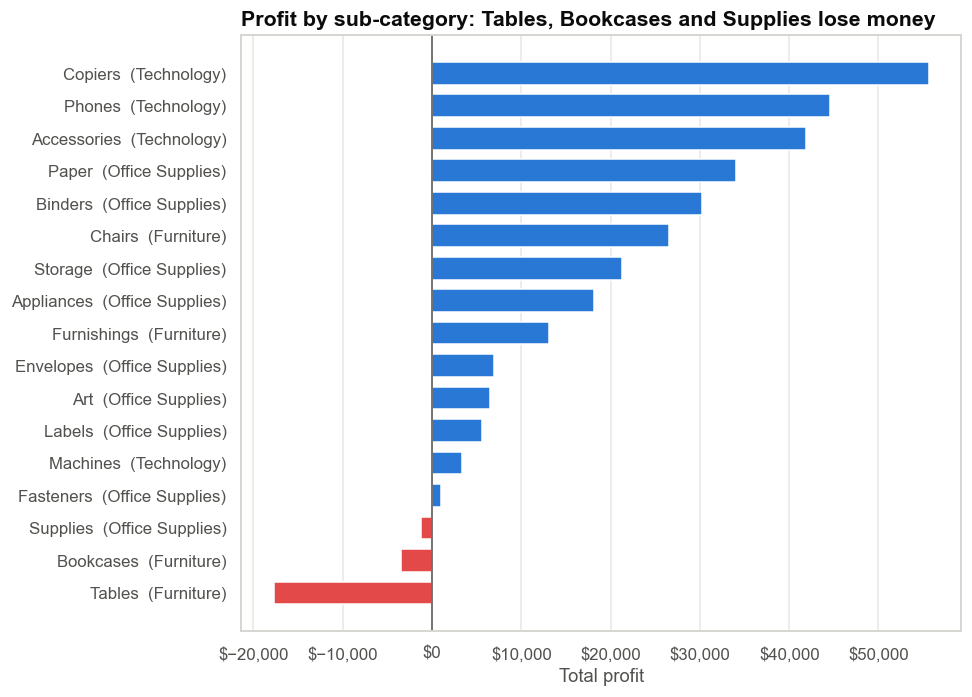

In [31]:
# Sort so the most profitable bar is on top of the horizontal chart
sub = sub_categories.sort_values("total_profit")
labels = sub["sub_category"] + "  (" + sub["category"] + ")"

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(labels, sub["total_profit"], color=sign_colors(sub["total_profit"]), height=0.7)
ax.axvline(0, color=GREY, linewidth=1)   # the zero line separates profit from loss

ax.set_title("Profit by sub-category: Tables, Bookcases and Supplies lose money")
ax.set_xlabel("Total profit")
ax.xaxis.set_major_formatter(dollars)
ax.grid(axis="y", visible=False)          # horizontal grid lines aren't needed on a bar chart

fig.tight_layout()
fig.savefig("images/profit_by_category.png")
plt.show()

### Chart 3: Region comparison
Sales and profit are very different in size, so they get **two side-by-side charts**
instead of one chart with two different y-axes (which is easy to misread).

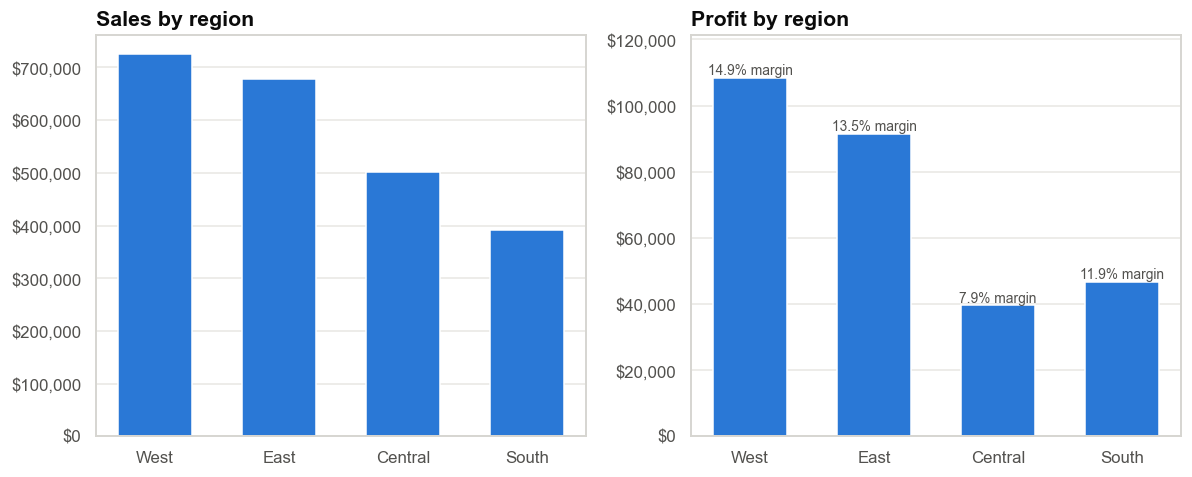

In [32]:
# Keep the same region order in both panels
reg = regions.sort_values("total_sales", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.bar(reg["region"], reg["total_sales"], color=BLUE, width=0.6)
ax1.set_title("Sales by region")
ax1.yaxis.set_major_formatter(dollars)

ax2.bar(reg["region"], reg["total_profit"], color=BLUE, width=0.6)
ax2.set_title("Profit by region")
ax2.yaxis.set_major_formatter(dollars)

# Write the profit margin above each profit bar
for x, profit, margin in zip(reg["region"], reg["total_profit"], reg["profit_margin_pct"]):
    ax2.text(x, profit, f"{margin}% margin", ha="center", va="bottom", fontsize=9, color=GREY)
ax2.set_ylim(top=reg["total_profit"].max() * 1.12)   # leave room above the tallest bar for its label

for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig("images/region_comparison.png")
plt.show()

### Chart 4: Discount vs profit

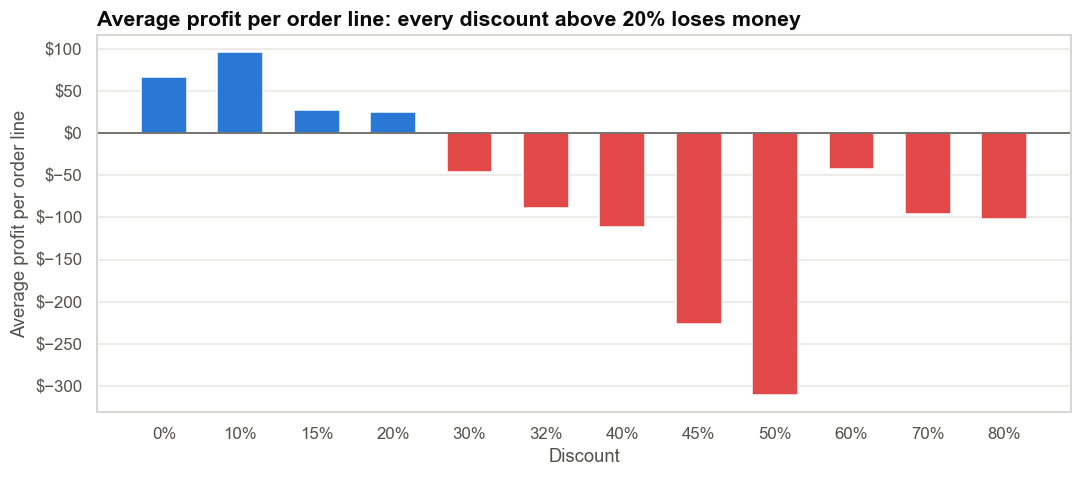

In [33]:
# Show discounts as percentages on the x-axis: 0.2 -> '20%'
disc_labels = (discounts["discount"] * 100).round().astype(int).astype(str) + "%"

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(disc_labels, discounts["avg_profit_per_line"],
       color=sign_colors(discounts["avg_profit_per_line"]), width=0.6)
ax.axhline(0, color=GREY, linewidth=1)

ax.set_title("Average profit per order line: every discount above 20% loses money")
ax.set_xlabel("Discount")
ax.set_ylabel("Average profit per order line")
ax.yaxis.set_major_formatter(dollars)
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig("images/discount_vs_profit.png")
plt.show()

### Chart 5: Return rate by region

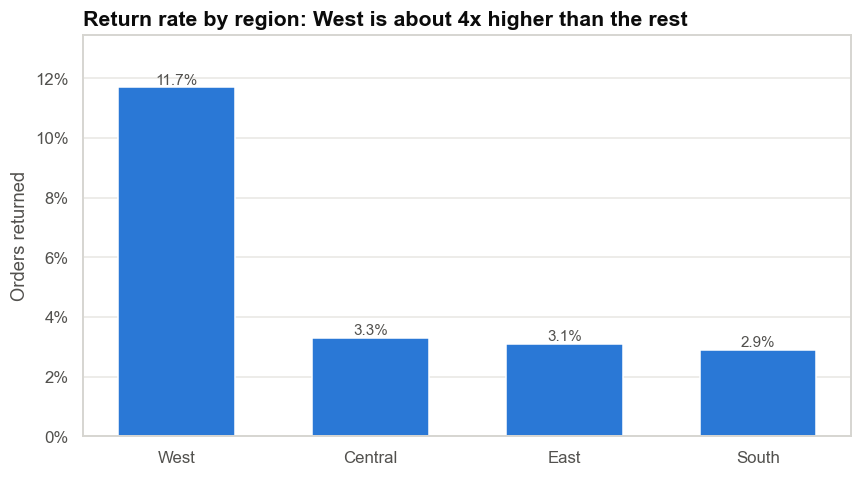

In [34]:
# Highest return rate on the left
rr = returns_by_region.sort_values("return_rate_pct", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(rr["region"], rr["return_rate_pct"], color=BLUE, width=0.6)

# Only 4 bars, so we can write the exact rate above each one
for x, rate in zip(rr["region"], rr["return_rate_pct"]):
    ax.text(x, rate, f"{rate}%", ha="center", va="bottom", fontsize=10, color=GREY)

ax.set_title("Return rate by region: West is about 4x higher than the rest")
ax.set_ylabel("Orders returned")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))   # 12 -> 12%
ax.set_ylim(top=rr["return_rate_pct"].max() * 1.15)
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig("images/return_rate_by_region.png")
plt.show()

## 6. Key numbers for the findings

In [35]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
print(f"Total sales:  ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}  ({total_profit / total_sales:.1%} margin)")

# How much profit do lines with a discount above 20% lose in total?
high_disc = df[df["discount"] > 0.2]
print(f"Order lines with discount > 20%: {len(high_disc):,} ({len(high_disc) / len(df):.0%} of all lines)")
print(f"Their combined profit: ${high_disc['profit'].sum():,.0f}")
print(f"...of which Furniture: ${high_disc.loc[high_disc['category'] == 'Furniture', 'profit'].sum():,.0f}")

Total sales:  $2,297,201
Total profit: $286,397  (12.5% margin)
Order lines with discount > 20%: 1,393 (14% of all lines)
Their combined profit: $-135,376
...of which Furniture: $-54,478


In [36]:
# West return rate compared with the average of the other three regions
west = returns_by_region.loc[returns_by_region["region"] == "West", "return_rate_pct"].iloc[0]
others = returns_by_region.loc[returns_by_region["region"] != "West", "return_rate_pct"].mean()
print(f"West return rate: {west}%  vs  other regions on average: {others:.1f}%  ({west / others:.1f}x)")

West return rate: 11.7%  vs  other regions on average: 3.1%  (3.8x)


In [37]:
# Always close the database connection when finished
conn.close()